In [1]:
'''Convert highly optimized university admission prediction models into serialized formats (pickle/joblib) ensuring compatibility and efficiency for deployment across diverse platforms.'''

'Convert highly optimized university admission prediction models into serialized formats (pickle/joblib) ensuring compatibility and efficiency for deployment across diverse platforms.'

In [2]:
# import required libraries
import os
import time
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
# load dataset and prepare regression features
df = pd.read_csv('Adm.csv')
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# optimize gradient boosting model using grid search
param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4]
}
grid = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=3)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print('best parameters:', grid.best_params_)
print('validation r2 score:', r2_score(y_test, best_model.predict(X_test)))

best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
validation r2 score: 0.92681952746984


In [5]:
# serialize optimized model with pickle and joblib
with open('admission_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

joblib.dump(best_model, 'admission_model.joblib')
print('models serialized successfully')

models serialized successfully


In [6]:
# evaluate file sizes for storage efficiency
pkl_size = os.path.getsize('admission_model.pkl') / 1024
joblib_size = os.path.getsize('admission_model.joblib') / 1024
sizes_df = pd.DataFrame({'format': ['pickle', 'joblib'], 'size_kb': [pkl_size, joblib_size]})
print(sizes_df)

   format     size_kb
0  pickle  134.608398
1  joblib  138.804688


In [7]:
# reload serialized models and verify prediction compatibility
with open('admission_model.pkl', 'rb') as f:
    loaded_pkl = pickle.load(f)

loaded_joblib = joblib.load('admission_model.joblib')

pred_orig = best_model.predict(X_test)
pred_pkl = loaded_pkl.predict(X_test)
pred_joblib = loaded_joblib.predict(X_test)

is_pkl_match = np.allclose(pred_orig, pred_pkl)
is_joblib_match = np.allclose(pred_orig, pred_joblib)
print('pickle prediction matches original:', is_pkl_match)
print('joblib prediction matches original:', is_joblib_match)

pickle prediction matches original: True
joblib prediction matches original: True


In [8]:
# benchmark inference speed of loaded models
start = time.time()
for _ in range(200):
    loaded_pkl.predict(X_test)
pkl_time = time.time() - start

start = time.time()
for _ in range(200):
    loaded_joblib.predict(X_test)
joblib_time = time.time() - start

timing_df = pd.DataFrame({'format': ['pickle', 'joblib'], 'time_sec': [pkl_time, joblib_time]})
print(timing_df)

   format  time_sec
0  pickle  0.197528
1  joblib  0.190709


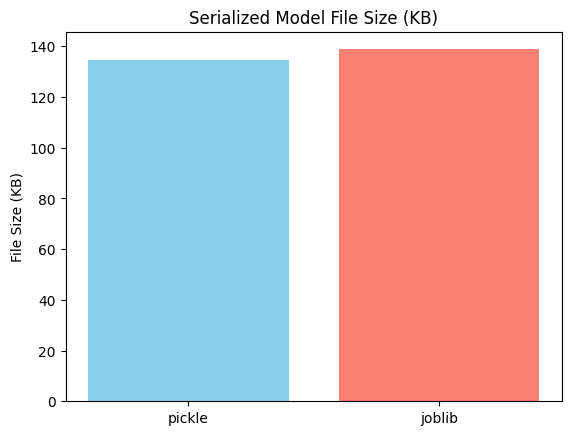

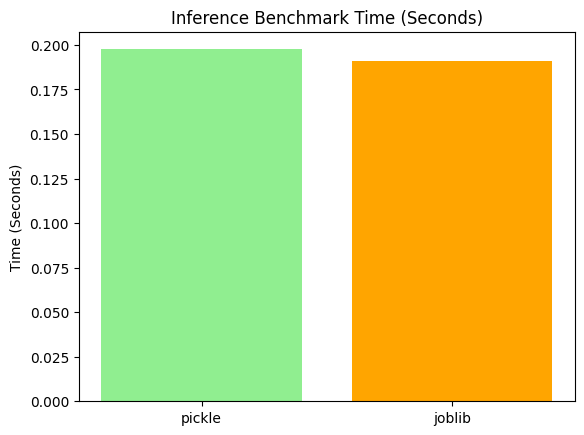

In [9]:
# plot comparison of serialization file size and inference time
plt.figure()
plt.bar(['pickle', 'joblib'], [pkl_size, joblib_size], color=['skyblue', 'salmon'])
plt.title('Serialized Model File Size (KB)')
plt.ylabel('File Size (KB)')
plt.show()

plt.figure()
plt.bar(['pickle', 'joblib'], [pkl_time, joblib_time], color=['lightgreen', 'orange'])
plt.title('Inference Benchmark Time (Seconds)')
plt.ylabel('Time (Seconds)')
plt.show()